# 05 - ELRS detector diagnosis: statistic or environment?

**Question:** Is the block-detection failure of notebook 04 (bench Pd
0.0636 at block-Pfa 1%, flat mixing ladder) caused by the occupancy
statistic or by the WiFi-dominated null, and which accumulation statistic
separates ELRS from that null?

Three experiments on the existing bench captures: null sensitivity
(pooled vs quiet vs leave-one-out), per-bin hit-count accumulation
statistics at 100 ms and 1 s scales, and D500 packet-timing from the
60 s captures. Phase 2 decision criteria in the conclusions cell.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tacet.dsp import cfar, features
from tacet.loaders import cs8
from tacet.loaders import manifest as manifest_mod

In [2]:
# --- Configuration ---
PFA_BIN = 0.01
PFA_BIN_ATTR = 1e-4
BLOCK_S = 0.1
WINDOW_1S_BLOCKS = 10
NFFT = 1024
BLOCK_PFA_TARGET = 0.01
SEED = 20260923
SATURATED_CONTROL_ID = "20260919T003427Z_control_000"
QUIET_CONTROL_ID = "20260919T005401Z_control_000"
D500_CAPTURES = (
    "20260921T185929Z_elrs-bench_000",
    "20260921T190035Z_elrs-bench_000",
    "20260921T190155Z_elrs-bench_000",
)
print("config ok")

config ok


In [3]:
def block_stats(z, fs):
    """Per-block statistics with per-bin hit-count retention.

    Computes everything the three experiments need in one pass:
    occupancy presence stats (pfa matrix), hit-count accumulation stats
    (pfa_attr matrix; noise expectation ~0.2 hits/bin), and the
    per-slice any-detection indicator for D500 burst counting.
    """
    z = features.remove_dc(z)
    _, _, S = features.spectrogram(z, fs, nfft=NFFT)
    floor = cfar.noise_floor(S)
    n_elig = S.shape[0] - (2 * features.DC_EXCLUDE_BINS + 1)
    center = S.shape[0] // 2
    dc = features.DC_EXCLUDE_BINS
    dc_rows = slice(center - dc, center + dc + 1)

    D = cfar.detect_bins(S, PFA_BIN)
    occ = D.sum(axis=0) / n_elig
    ratio = S / floor[np.newaxis, :]
    ratio[dc_rows, :] = 0.0

    D_attr = cfar.detect_bins(S, PFA_BIN_ATTR)
    hits = D_attr.sum(axis=1).astype(np.int64)
    hits[dc_rows] = 0
    total = int(hits.sum())
    hit_bins = hits[hits > 0]
    return {
        "max_occ": float(occ.max()),
        "excess_db": float(10.0 * np.log10(ratio.max())),
        "n_bins_ge1": int((hits >= 1).sum()),
        "max_hits": int(hits.max()),
        "hhi": float(((hit_bins / total) ** 2).sum()) if total else 0.0,
        "total_hits": total,
        "hits": hits,
        "any_occ": D_attr.any(axis=0),
    }


def roc_auc(y_true, scores):
    """Mann-Whitney AUC: P(positive > negative) + 0.5 P(tie)."""
    y = np.asarray(y_true, dtype=bool)
    pos = np.asarray(scores)[y]
    neg = np.asarray(scores)[~y]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    return float((pos[:, None] > neg[None, :]).mean()
                 + 0.5 * (pos[:, None] == neg[None, :]).mean())


def pd_at_pfa(pos_scores, null_scores, pfa):
    thr = np.quantile(null_scores, 1.0 - pfa)
    return float((np.asarray(pos_scores) > thr).mean()), float(thr)


print("helpers ok")

helpers ok


In [4]:
# One streaming pass over the 13 captures: per-block stats, per-1s-window
# hit sums, and (for the three 60 s captures) D500 burst events.
entries = manifest_mod.query()
signals = [e for e in entries if e["protocol"] == "elrs"]
controls = [e for e in entries
            if e["protocol"] == "noise" and e["id"] != SATURATED_CONTROL_ID]

import time

t0 = time.time()
rows = []
rows_1s = []
d500 = []
for i, e in enumerate(signals + controls, 1):
    fs = e["sample_rate_sps"]
    n_block = int(BLOCK_S * fs)
    capture_rows = []
    burst_events = 0
    prev_occ = False
    hits_1s_acc = None
    n_in_group = 0
    for z in cs8.iter_cs8_blocks(str(Path(e["channels"][0]["path"])), n_block):
        st = block_stats(z, fs)
        occ_now = st.pop("any_occ")
        if e["id"] in D500_CAPTURES:
            occ_full = np.r_[prev_occ, occ_now]
            burst_events += int((occ_full[1:] & ~occ_full[:-1]).sum())
            prev_occ = bool(occ_now[-1])
        hits = st.pop("hits")
        st["capture_id"] = e["id"]
        st["label"] = e["protocol"]
        capture_rows.append(st)
        hits_1s_acc = hits.copy() if hits_1s_acc is None else hits_1s_acc + hits
        n_in_group += 1
        if n_in_group == WINDOW_1S_BLOCKS:
            ge1 = int((hits_1s_acc >= 1).sum())
            block_ge1 = np.mean([r["n_bins_ge1"] for r in capture_rows[-WINDOW_1S_BLOCKS:]])
            hit_bins = hits_1s_acc[hits_1s_acc > 0]
            total = int(hits_1s_acc.sum())
            rows_1s.append({
                "capture_id": e["id"], "label": e["protocol"],
                "n_bins_ge1_1s": ge1,
                "scaling_ratio": float(ge1 / block_ge1) if block_ge1 else 0.0,
                "hhi_1s": float(((hit_bins / total) ** 2).sum()) if total else 0.0,
            })
            hits_1s_acc = None
            n_in_group = 0
    rows.extend(capture_rows)
    if e["id"] in D500_CAPTURES:
        d500.append({
            "capture_id": e["id"],
            "burst_rate_hz": burst_events / e["duration_s"],
            "n_burst_events": burst_events,
        })
    print(f"[{i:2d}/{len(signals) + len(controls)}] {e['id']} "
          f"({len(capture_rows)} blocks, {time.time() - t0:.0f} s)", flush=True)

df = pd.DataFrame(rows)
df_1s = pd.DataFrame(rows_1s)
d500_df = pd.DataFrame(d500)
print(f"blocks {len(df)}, 1s windows {len(df_1s)}")

[ 1/13] 20260919T004638Z_elrs-bench_000 (30 blocks, 6 s)
[ 2/13] 20260919T004805Z_elrs-bench_000 (30 blocks, 13 s)
[ 3/13] 20260919T005239Z_elrs-bench_000 (30 blocks, 19 s)
[ 4/13] 20260919T005242Z_elrs-bench_000 (30 blocks, 25 s)
[ 5/13] 20260919T005913Z_elrs-bench_000 (30 blocks, 31 s)
[ 6/13] 20260921T185929Z_elrs-bench_000 (600 blocks, 151 s)
[ 7/13] 20260921T190035Z_elrs-bench_000 (600 blocks, 270 s)
[ 8/13] 20260921T190155Z_elrs-bench_000 (600 blocks, 391 s)
[ 9/13] 20260919T003513Z_control_000 (10 blocks, 393 s)
[10/13] 20260919T005401Z_control_000 (30 blocks, 399 s)
[11/13] 20260919T005404Z_control_000 (30 blocks, 405 s)
[12/13] 20260919T005408Z_control_000 (30 blocks, 411 s)
[13/13] 20260921T190315Z_control_000 (600 blocks, 526 s)
blocks 2650, 1s windows 265


In [5]:
# Experiment 1: null sensitivity for the notebook-04 statistic
# (max_occupied_fraction). Pd at block-Pfa 1% under: pooled null, quiet
# control only, and leave-one-out per control.
sig_occ = df[df["label"] == "elrs"]["max_occ"].to_numpy()
ctl = df[df["label"] == "noise"]
pooled = ctl["max_occ"].to_numpy()
quiet = ctl[ctl["capture_id"] == QUIET_CONTROL_ID]["max_occ"].to_numpy()

pd_pool, thr_pool = pd_at_pfa(sig_occ, pooled, BLOCK_PFA_TARGET)
pd_quiet, thr_quiet = pd_at_pfa(sig_occ, quiet, BLOCK_PFA_TARGET)
loo = []
for cid, grp in ctl.groupby("capture_id"):
    others = ctl[ctl["capture_id"] != cid]["max_occ"].to_numpy()
    p, _ = pd_at_pfa(sig_occ, others, BLOCK_PFA_TARGET)
    loo.append({"held_out": cid, "null_blocks": len(others), "pd": p})
null_sens = pd.DataFrame(loo)
print(f"pooled null ({len(pooled)} blocks): Pd {pd_pool:.4f} @ thr {thr_pool:.4f}")
print(f"quiet null ({len(quiet)} blocks):  Pd {pd_quiet:.4f} @ thr {thr_quiet:.4f}")
print(f"pooled AUC {roc_auc(df['label'] == 'elrs', df['max_occ']):.4f}")
null_sens

                       held_out  null_blocks        pd
0  20260919T003513Z_control_000          690  0.063590
1  20260919T005401Z_control_000          670  0.063590
2  20260919T005404Z_control_000          670  0.063590
3  20260919T005408Z_control_000          670  0.063590
4  20260921T190315Z_control_000          100  0.207692

pooled null (700 blocks): Pd 0.0636 @ thr 0.2542
quiet null (30 blocks):  Pd 0.9256 @ thr 0.1668
pooled AUC 0.6686


In [6]:
# Experiment 2a: accumulation statistics at block scale (100 ms).
y = (df["label"] == "elrs").to_numpy()
results = []
for col in ("n_bins_ge1", "max_hits", "hhi", "total_hits"):
    scores = df[col].to_numpy(dtype=float)
    auc = roc_auc(y, scores)
    pd_p, _ = pd_at_pfa(scores[y], df.loc[~y, col].to_numpy(dtype=float), BLOCK_PFA_TARGET)
    q = ctl[ctl["capture_id"] == QUIET_CONTROL_ID][col].to_numpy(dtype=float)
    pd_q, _ = pd_at_pfa(scores[y], q, BLOCK_PFA_TARGET)
    results.append({"statistic": col, "auc": auc,
                    "pd_pooled": pd_p, "pd_quiet_null": pd_q})
block_scale = pd.DataFrame(results)
block_scale

    statistic       auc  pd_pooled  pd_quiet_null
0  n_bins_ge1  0.711186   0.069231       0.904103
1    max_hits  0.604386   0.030256       0.995385
2         hhi  0.421058   0.004615       0.070256
3  total_hits  0.595271   0.024103       0.991795

In [7]:
# Experiment 2b: accumulation at the 1 s scale (unit = 1 s window).
y1 = (df_1s["label"] == "elrs").to_numpy()
results = []
for col in ("n_bins_ge1_1s", "scaling_ratio", "hhi_1s"):
    scores = df_1s[col].to_numpy(dtype=float)
    auc = roc_auc(y1, scores)
    null_1s = df_1s.loc[~y1, col].to_numpy(dtype=float)
    quiet_1s = df_1s[df_1s["capture_id"] == QUIET_CONTROL_ID][col].to_numpy(dtype=float)
    pd_p, _ = pd_at_pfa(scores[y1], null_1s, BLOCK_PFA_TARGET)
    pd_q, _ = pd_at_pfa(scores[y1], quiet_1s, BLOCK_PFA_TARGET)
    results.append({"statistic": col, "auc": auc,
                    "pd_pooled": pd_p, "pd_quiet_null": pd_q})
scale_1s = pd.DataFrame(results)
print(f"1s windows: {int(y1.sum())} signal vs {int((~y1).sum())} control")
scale_1s

       statistic       auc  pd_pooled  pd_quiet_null
0  n_bins_ge1_1s  0.557949   0.000000       0.984615
1  scaling_ratio  0.189597   0.000000       0.000000
2         hhi_1s  0.528132   0.005128       0.010256

1s windows: 195 signal vs 70 control


In [8]:
# Experiment 3: D500 packet timing from the 60 s captures
# (burst events on the per-slice any-detection indicator).
d500_df["nominal_hz"] = 500.0
print("nominal ~500 packets/s is external knowledge (unverified prior)")
d500_df

                        capture_id  burst_rate_hz  n_burst_events  nominal_hz
0  20260921T185929Z_elrs-bench_000    1198.100000           71886       500.0
1  20260921T190035Z_elrs-bench_000    1206.066667           72364       500.0
2  20260921T190155Z_elrs-bench_000    1275.033333           76502       500.0

nominal ~500 packets/s is external knowledge (unverified prior)


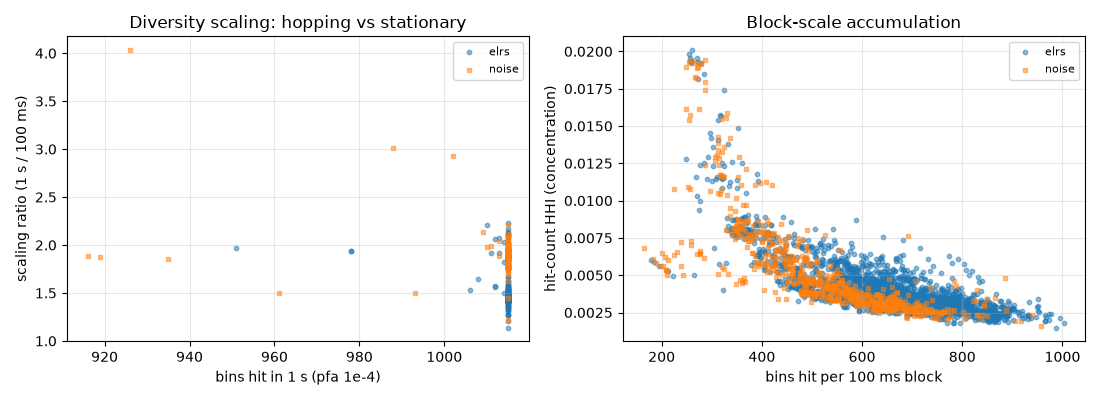

In [9]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
for lab, marker in (("elrs", "o"), ("noise", "s")):
    grp = df_1s[df_1s["label"] == lab]
    plt.scatter(grp["n_bins_ge1_1s"], grp["scaling_ratio"],
                s=10, alpha=0.5, marker=marker, label=lab)
plt.xlabel("bins hit in 1 s (pfa 1e-4)")
plt.ylabel("scaling ratio (1 s / 100 ms)")
plt.title("Diversity scaling: hopping vs stationary")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for lab, marker in (("elrs", "o"), ("noise", "s")):
    grp = df[df["label"] == lab]
    plt.scatter(grp["n_bins_ge1"], grp["hhi"],
                s=10, alpha=0.5, marker=marker, label=lab)
plt.xlabel("bins hit per 100 ms block")
plt.ylabel("hit-count HHI (concentration)")
plt.title("Block-scale accumulation")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusions (measured, from the outputs above)

**(1) The notebook-04 failure is the environment, not the statistic.**
The pooled-null result reproduces notebook 04 exactly (Pd 0.0636 at
threshold 0.2542 over 700 control blocks, pooled AUC 0.6686). Against
the quiet control 20260919T005401Z_control_000 alone (30 blocks,
threshold 0.1668), the same signal blocks and the same statistic reach
Pd 0.9256. The leave-one-out table shows the pooled null is dominated
by one capture: holding out the 60 s control 20260921T190315Z raises
Pd to 0.2077 (100-block null), while holding out any other control
leaves Pd at 0.0636. Most of the failure is the WiFi-heavy null, above
all that one capture.

**(2) Best accumulation statistic: n_bins_ge1 at the 100 ms scale.** It
has the best AUC of the four block-scale candidates (0.7112) and
reaches Pd 0.9041 against the quiet null (Pd 0.0692 against the pooled
null). max_hits and total_hits clear the quiet criterion harder (0.9954
and 0.9918) but rank blocks worse overall (AUC 0.6044 and 0.5953,
pooled Pd 0.0303 and 0.0241), so their high quiet Pd says more about
the low quiet threshold than about separation. hhi is anti-selective
(AUC 0.4211): hopping spreads hits across bins, so ELRS blocks look
less concentrated than WiFi bursts. At the 1 s scale nothing separates:
best AUC 0.5579 (n_bins_ge1_1s), and the scaling ratio is strongly
anti-selective (AUC 0.1896, Pd 0.0000 against both nulls), so the
hopping-scales-up-diversity hypothesis is not supported on this data;
both classes saturate at roughly 920 to 1010 bins hit in 1 s (left
scatter) because per-slice noise false alarms at pfa 1e-4 already cover
most bins within a second. Caveat: the quiet null is 30 blocks (3
one-second windows at the 1 s scale), so its 1% quantile is effectively
the maximum of a handful of samples and every quiet-null Pd above is
coarse.

**(3) D500 timing: measured burst rates are 1198.1, 1206.1 and 1275.0
events/s** (71886, 72364 and 76502 events over the 60 s captures), that
is 2.40x to 2.55x the nominal 500 packets/s. Both sides of that
comparison are unreliable: the nominal rate is unverified external
knowledge, and the indicator counts empty-to-occupied transitions of
any eligible bin, which fragments bursts (per-slice noise false alarms
and fades), so it over-counts packets. CFAR-bin timing does not resolve
packet rate; the dechirp path needs measured chirp parameters instead.

**(4) Recommended Phase 2: cleaner-site captures.** By the agreed
criteria, no accumulation statistic reaches Pd 0.9 against the pooled
null (best 0.0692), while three block-scale statistics clear the
quiet-null route (n_bins_ge1 0.9041, max_hits 0.9954, total_hits
0.9918) with the environment caveat documented. Since that route rests
on a 30-block null, the decisive next measurement is a larger quiet
null from a cleaner site: if quiet-null Pd holds at or above 0.9 on it,
promotion to the library follows the agreed criteria. The dechirp path
stays the fallback and needs verified chirp parameters first.